**Importing required libraries**

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pickle_mapping = {
    'customer_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/customer_clean.pkl',
    'invent_movement_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/inventory_movement_clean.pkl',
    'lost_sales_log_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/lost_sales_log_clean.pkl',
    'open_invent_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/Open_inventory_clean.pkl',
    'price_changes_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/price_changes_cleaned.pkl',
    'products_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/Products_clean.pkl',
    'promotion_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/promotion_clean.pkl',
    'purchase_order_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/purchase_order_clean.pkl',
    'purchase_order_item_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/purchase_order_item_clean.pkl',
    'sales_return_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/sales_return_cleaned.pkl',
    'sales_return_items_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/sales_return_items_clean.pkl',
    'stores_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/stores_clean.pkl',
    'suppliers_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/suppliers_clean.pkl',
    'transaction_items_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/transaction_items_clean.pkl',
    'transactions_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/transactions_clean.pkl'

}

**Loading the datasets**

In [3]:
#storing the dataset in one cabinet(dataframes)
dataframes = {file_name: pd.read_pickle(file_path) for file_name,file_path in pickle_mapping.items()}

In [4]:
dataframes.keys()

dict_keys(['customer_df', 'invent_movement_df', 'lost_sales_log_df', 'open_invent_df', 'price_changes_df', 'products_df', 'promotion_df', 'purchase_order_df', 'purchase_order_item_df', 'sales_return_df', 'sales_return_items_df', 'stores_df', 'suppliers_df', 'transaction_items_df', 'transactions_df'])

In [5]:
data_name = ['customer_df', 'invent_movement_df', 'lost_sales_log_df', 'open_invent_df', 'price_changes_df', 'products_df', 'promotion_df', 'purchase_order_item_df', 'purchase_order_df', 'sales_return_df', 'sales_return_items_df', 'stores_df', 'suppliers_df', 'transaction_items_df', 'transactions_df']

### Loading all the dataset

In [6]:
customer_df=dataframes['customer_df']
invent_movement_df=dataframes['invent_movement_df']
lost_sales_log_df=dataframes['lost_sales_log_df']
open_invent_df=dataframes['open_invent_df']
price_changes_df=dataframes['price_changes_df']
products_df=dataframes['products_df']
promotion_df=dataframes['promotion_df']
purchase_order_item_df=dataframes['purchase_order_item_df']
purchase_order_df=dataframes['purchase_order_df']
sales_return_df=dataframes['sales_return_df']
stores_df=dataframes['stores_df']
suppliers_df=dataframes['suppliers_df']
transaction_items_df=dataframes['transaction_items_df']
transactions_df=dataframes['transactions_df']

# Exploratory Data Anlysis (EDA)

# Preparing sales records

In [ ]:
# Filtering out voided sales
transactions_complete_df = transactions_df[transactions_df['transaction_status']=='Completed']
print('All transaction Records:',transactions_df.shape)                   
print('All complete records:',transactions_complete_df.shape)
print('All voided records:', len(transactions_df)-len(transactions_complete_df))


All transaction Records: (100000, 10)
All complete records: (98504, 10)
All voided records: 1496


In [135]:
# Join item-level sales to transaction date, branch, customer and payment information
trans_df = transaction_items_df.merge(
    transactions_complete_df[
        ['transaction_id', 'transaction_datetime', 'store_id',
         'customer_id', 'payment_method']
    ],
    on='transaction_id',
    how='inner'
)

# Make sure the date column is stored as a datetime
trans_df['transaction_datetime'] = pd.to_datetime(trans_df['transaction_datetime'],format='mixed',errors='coerce')

# Add product name and category
trans_df = trans_df.merge(
    products_df[['product_id', 'product_name', 'category']],
    on='product_id',
    how='left'
)

# Add branch name and county
trans_df = trans_df.merge(
    stores_df[['store_id', 'store_name', 'county']],
    on='store_id',
    how='left'
)

# Calculate cost of goods sold and gross profit before refunds
trans_df['cost_of_goods_sold'] = round(trans_df['quantity'] * trans_df['unit_cost_at_sale'],2)
trans_df['profit_before_refunds'] =round( trans_df['line_net_amount'] - trans_df['cost_of_goods_sold'],2)

trans_df.head()

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,product_name,category,store_name,county,cost_of_goods_sold,profit_before_refunds
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,Tetracycline 1% Eye ointment,"Eye, Ear & Nose",SimPharm Embakasi,Nairobi,87.71,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Glimepiride 2 mg Tablets,Diabetes,SimPharm Langas,Uasin Gishu,137.06,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Cetirizine 10 mg Tablets,Respiratory & Allergy,SimPharm Langas,Uasin Gishu,73.38,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,Gliclazide 80 mg Tablets,Diabetes,SimPharm Kisumu Central,Kisumu,125.81,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,Losartan 50 mg Tablets,Cardiovascular,SimPharm Embakasi,Nairobi,111.82,33.18


# Sales intelligence

## Net sales, refunds, gross profit and margin

In [138]:
# Total sales before refunds
total_sales = trans_df['line_net_amount'].sum()

# Total product cost and gross profit before refunds
total_cost = trans_df['cost_of_goods_sold'].sum()
total_profit_before_refunds = trans_df['profit_before_refunds'].sum().round(2)

# Total refunds recorded
total_refunds = sales_return_df['refund_amount'].sum()

sales_summary = pd.DataFrame({
    'measure': ['Net sales before refunds', 'Refunds', 'Sales after refunds',
                'Cost of goods sold', 'Gross profit before refunds'],
    'amount_kes': [
        total_sales,
        total_refunds,
        round(total_sales - total_refunds,2),
        total_cost,
        total_profit_before_refunds
    ]
})

sales_summary

,measure,amount_kes
0,Net sales before refunds,51071364.75
1,Refunds,216716.00
2,Sales after refunds,50854648.75
3,Cost of goods sold,37736141.54
4,Gross profit before refunds,13335223.21


In [139]:
# Gross margin before refunds
gross_margin_before_refunds = round((total_profit_before_refunds / total_sales) * 100,2 )

print(f'Gross margin before refunds: {gross_margin_before_refunds}%')

Gross margin before refunds: 26.11%


## Sales and profit by branch

In [142]:
branch_performance = (
    trans_df.groupby(['store_id', 'store_name', 'county'], as_index=False)
    .agg(
        net_sales=('line_net_amount', 'sum'),
        gross_profit_before_refunds=('profit_before_refunds', 'sum'),
        units_sold=('quantity', 'sum'),
        transactions=('transaction_id', 'nunique'))
)

branch_performance['gross_margin_pct'] = round((branch_performance['gross_profit_before_refunds'] /branch_performance['net_sales'] * 100),2)
branch_performance = branch_performance.sort_values('net_sales', ascending=False)
display(branch_performance)

,store_id,store_name,county,net_sales,gross_profit_before_refunds,units_sold,transactions,gross_margin_pct
0,ST01,SimPharm Westlands,Nairobi,5794218.65,1518027.54,35252,11084,26.20
1,ST02,SimPharm Embakasi,Nairobi,5133402.75,1345798.48,31364,9909,26.22
3,ST04,SimPharm Mombasa Island,Mombasa,4710191.30,1225252.61,29292,9224,26.01
9,ST10,SimPharm Ruaka,Kiambu,4675793.70,1221510.97,26652,8502,26.12
2,ST03,SimPharm Nyali,Mombasa,4440826.55,1158078.10,26220,8450,26.08
6,ST07,SimPharm Nakuru Town,Nakuru,4290289.20,1123336.39,25729,8010,26.18
5,ST06,SimPharm Kisumu Central,Kisumu,4057265.55,1054534.44,25028,7879,25.99
8,ST09,SimPharm Thika,Kiambu,3963158.35,1031945.56,25748,8083,26.04
10,ST11,SimPharm Eldoret Town,Uasin Gishu,3927787.95,1021838.89,24004,7622,26.02
4,ST05,SimPharm Milimani,Kisumu,3602625.15,940066.37,22828,7187,26.09


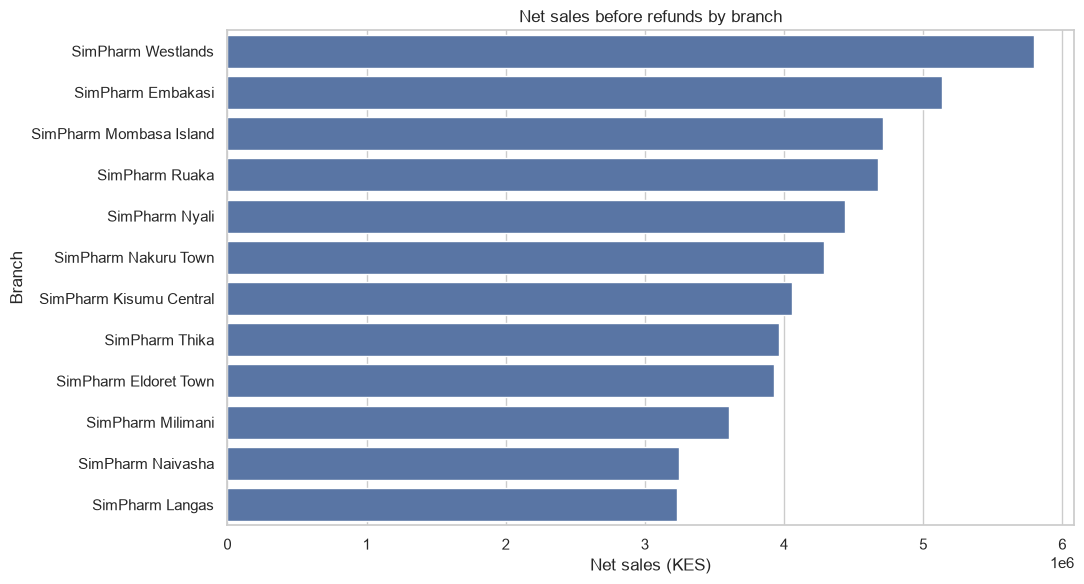

In [143]:
plt.figure(figsize=(11, 6))
sns.barplot(data=branch_performance, x='net_sales', y='store_name')
plt.title('Net sales before refunds by branch')
plt.xlabel('Net sales (KES)')
plt.ylabel('Branch')
plt.tight_layout()
plt.show()

## Sales by county and by category

In [145]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,product_name,category,store_name,county,cost_of_goods_sold,profit_before_refunds
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,Tetracycline 1% Eye ointment,"Eye, Ear & Nose",SimPharm Embakasi,Nairobi,87.71,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Glimepiride 2 mg Tablets,Diabetes,SimPharm Langas,Uasin Gishu,137.06,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Cetirizine 10 mg Tablets,Respiratory & Allergy,SimPharm Langas,Uasin Gishu,73.38,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,Gliclazide 80 mg Tablets,Diabetes,SimPharm Kisumu Central,Kisumu,125.81,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,Losartan 50 mg Tablets,Cardiovascular,SimPharm Embakasi,Nairobi,111.82,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,Vitamin B complex Tablets,Vitamins & Supplements,SimPharm Ruaka,Kiambu,58.06,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,Ibuprofen 100 mg/5 mL Suspension,Pain & Fever,SimPharm Ruaka,Kiambu,88.14,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,Amlodipine 5 mg Tablets,Cardiovascular,SimPharm Ruaka,Kiambu,121.72,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,Malaria rapid diagnostic test Test kit,First Aid & Medical Supplies,SimPharm Ruaka,Kiambu,66.20,31.80


In [ ]:
print(50*'=','sales_by_county',50*'=')
sales_by_county = (
    trans_df.groupby('county', as_index=False)
    .agg(net_sales=('line_net_amount', 'sum'),
         gross_profit_before_refunds=('profit_before_refunds', 'sum'))
    .sort_values('net_sales', ascending=False)
)
display(sales_by_county)

print(50*'=','sales_by_category',50*'=')

sales_by_category = (
    trans_df.groupby('category', as_index=False)
    .agg(net_sales=('line_net_amount', 'sum'),
         gross_profit_before_refunds=('profit_before_refunds', 'sum'),
         units_sold=('quantity', 'sum'))
    .sort_values('net_sales', ascending=False)
)
display(sales_by_category)

print(50*'=','sales_by_product_name',50*'=')
sales_by_product = (
    trans_df.groupby('product_name', as_index=False)
    .agg(net_sales=('line_net_amount', 'sum'),
         gross_profit_before_refunds=('profit_before_refunds', 'sum'),
         units_sold=('quantity', 'sum'))
    .sort_values('net_sales', ascending=False)
)
display(sales_by_product)


================================================== sales_by_county ==================================================


,county,net_sales,gross_profit_before_refunds
3,Nairobi,10927621.40,2863826.02
2,Mombasa,9151017.85,2383330.71
0,Kiambu,8638952.05,2253456.53
1,Kisumu,7659890.70,1994600.81
4,Nakuru,7537136.45,1971338.22
5,Uasin Gishu,7156746.30,1868670.92


================================================== sales_by_category ==================================================


,category,net_sales,gross_profit_before_refunds,units_sold
12,Vitamins & Supplements,7673197.25,1945216.74,26711
4,Diabetes,6003779.55,1732141.44,18581
11,Respiratory & Allergy,5691964.45,1432235.84,38601
0,Antibiotics,5216140.00,1222533.64,36567
2,Cardiovascular,4704666.85,1245562.02,37700
3,Dermatology,4497867.75,1199752.00,18202
7,Gastrointestinal,3989183.65,1076565.39,38385
6,First Aid & Medical Supplies,3421809.90,921567.03,17746
9,Pain & Fever,3050071.15,788807.84,42077
10,Reproductive Health,2625133.30,739808.65,15621


================================================== sales_by_product_name ==================================================


,product_name,net_sales,gross_profit_before_refunds,units_sold
24,Blood glucose test strips 50 strips Test strips,1773372.0,578945.64,1308
27,Calcium/Vitamin D3 600 mg/400 IU Tablets,1292677.0,339561.68,3284
19,Beclometasone 100 mcg/dose Inhaler,1261800.0,234053.28,1716
106,Multivitamin Tablets,1067771.0,259225.96,2936
112,Omega-3 fish oil 1000 mg Softgel capsules,1066755.0,231361.88,1096
...,...,...,...,...
124,Promethazine 25 mg Tablets,63719.4,21173.16,1264
100,Metoclopramide 10 mg Tablets,62974.0,20671.90,1369
94,Mebendazole 100 mg Tablets,45994.0,9388.75,765
136,Sulfadoxine/Pyrimethamine 500/25 mg Tablets,42760.5,13915.62,744


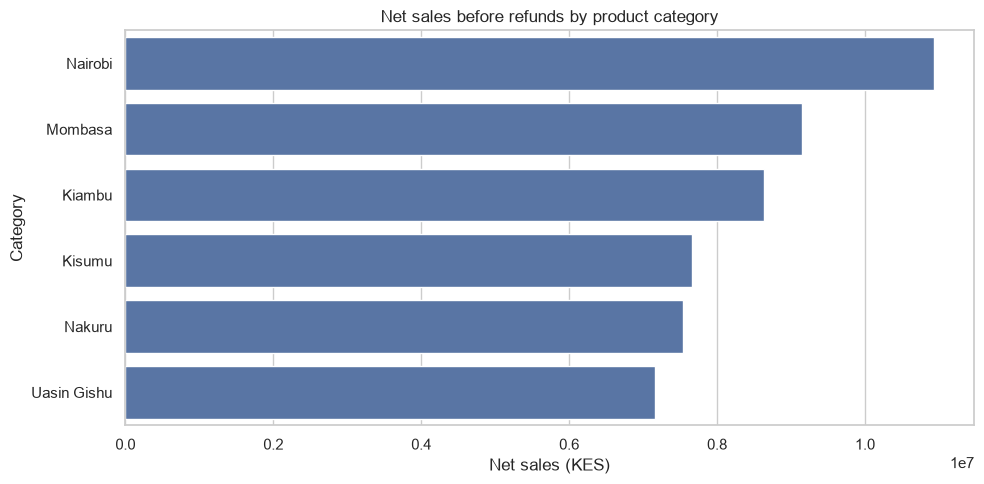

In [150]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sales_by_county, x='net_sales', y='county')
plt.title('Net sales before refunds by product category')
plt.xlabel('Net sales (KES)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

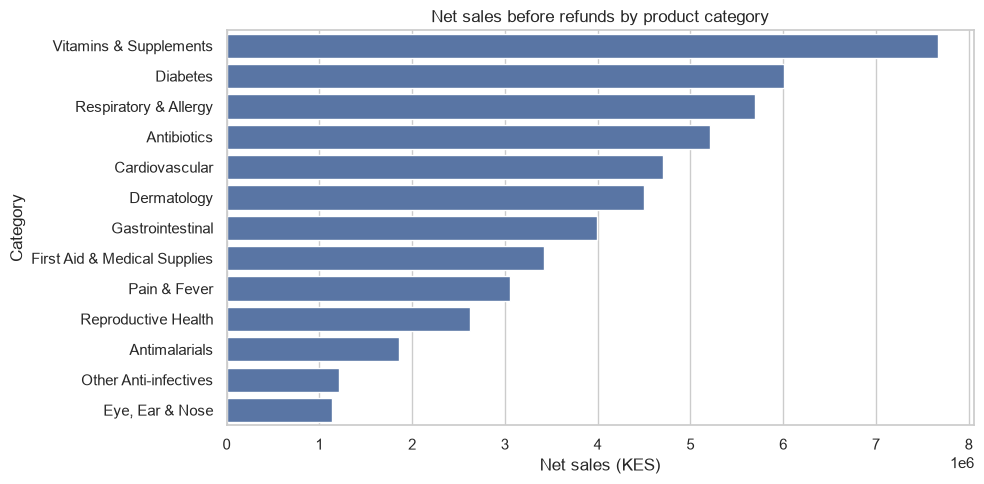

In [151]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sales_by_category, x='net_sales', y='category')
plt.title('Net sales before refunds by product category')
plt.xlabel('Net sales (KES)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


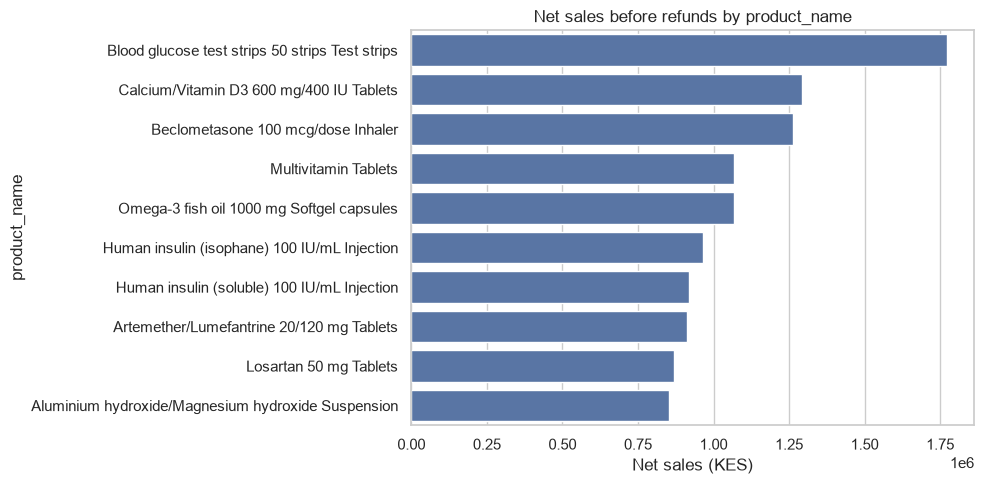

In [158]:
top_10_products=sales_by_product.head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10_products, x='net_sales', y='product_name')
plt.title('Net sales before refunds by product_name')
plt.xlabel('Net sales (KES)')
plt.ylabel('product_name')
plt.tight_layout()
plt.show()


## Average basket value and units per transaction

In [162]:
basket_df = (
    trans_df.groupby('transaction_id', as_index=False)
    .agg(
        basket_value=('line_net_amount', 'sum'),
        units_in_basket=('quantity', 'sum'),
        number_of_product_lines=('product_id', 'count'),
        store_id=('store_id', 'first'),
        payment_method=('payment_method', 'first'),
        customer_id=('customer_id', 'first'),
        transaction_datetime=('transaction_datetime', 'first')
    )
)

print('Average basket value (KES):', round(basket_df['basket_value'].mean(), 2))
print('Median basket value (KES):', round(basket_df['basket_value'].median(), 2))
print('Average units per transaction:', round(basket_df['units_in_basket'].mean(), 2))


Average basket value (KES): 518.47
Median basket value (KES): 390.0
Average units per transaction: 3.17


In [31]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,31.80


### product contribution share

**Investigating top 10 products generating the highest revenue and highest profit**

In [32]:
#top_10 higest revenue generating product

revenue_by_product = trans_df.groupby('product_id')['line_net_amount'].sum()
revenue_by_product.to_frame()
#top ten high revenue generating  products
revenue_by_product=revenue_by_product.to_frame().sort_values('line_net_amount',ascending=False)
revenue_by_product

,line_net_amount
product_id,
P060,1773372.0
P097,1292677.0
P084,1261800.0
P092,1067771.0
P099,1066755.0
...,...
P082,63719.4
P073,62974.0
P126,45994.0


In [33]:
# merging the products names and categories
revenue_by_product=pd.merge(
    revenue_by_product,
    products_df[['product_id','product_name','category']],
    on = 'product_id',
    how = 'left'
)
revenue_by_product.head(10)

,product_id,line_net_amount,product_name,category
0,P060,1773372.0,Blood glucose test strips 50 strips Test strips,Diabetes
1,P097,1292677.0,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements
2,P084,1261800.0,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy
3,P092,1067771.0,Multivitamin Tablets,Vitamins & Supplements
4,P099,1066755.0,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements
5,P059,965004.5,Human insulin (isophane) 100 IU/mL Injection,Diabetes
6,P058,920040.0,Human insulin (soluble) 100 IU/mL Injection,Diabetes
7,P033,912145.5,Artemether/Lumefantrine 20/120 mg Tablets,Antimalarials
8,P044,869615.0,Losartan 50 mg Tablets,Cardiovascular
9,P065,853895.0,Aluminium hydroxide/Magnesium hydroxide Suspen...,Gastrointestinal


In [34]:
#top 10 highest profit generating product
profit_by_product = trans_df.groupby('product_id')['profit'].sum().round(2)
profit_by_product.to_frame()
#top ten high profit generating  products
profit_by_product=profit_by_product.to_frame().sort_values('profit',ascending=False)
profit_by_product

,profit
product_id,
P060,578945.64
P097,339561.68
P059,265880.40
P092,259225.96
P083,258327.49
...,...
P089,15376.29
P075,14833.85
P038,13915.62


In [35]:
# merging the products names and categories
profit_by_product=pd.merge(
    profit_by_product,
    products_df[['product_id','product_name','category']],
    on = 'product_id',
    how = 'left'
)
profit_by_product.head(10)

,product_id,profit,product_name,category
0,P060,578945.64,Blood glucose test strips 50 strips Test strips,Diabetes
1,P097,339561.68,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements
2,P059,265880.40,Human insulin (isophane) 100 IU/mL Injection,Diabetes
3,P092,259225.96,Multivitamin Tablets,Vitamins & Supplements
4,P083,258327.49,Montelukast 10 mg Tablets,Respiratory & Allergy
5,P131,254999.36,Levonorgestrel 1.5 mg Tablets,Reproductive Health
6,P058,248840.52,Human insulin (soluble) 100 IU/mL Injection,Diabetes
7,P033,240123.60,Artemether/Lumefantrine 20/120 mg Tablets,Antimalarials
8,P084,234053.28,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy
9,P099,231361.88,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements


### Checking in each store which product is generating the highest profit and revenue

In [36]:

# Aggregate revenue by store and product
revenue_by_product_store = (trans_df.groupby(['store_id', 'product_id'], as_index=False)
['line_net_amount'].sum().rename(columns={'line_net_amount': 'total_revenue'}))

# Merge product names and categories
revenue_by_product_store = revenue_by_product_store.merge(
    products_df[['product_id', 'product_name', 'category']],
    on='product_id',
    how='left'
)
# Merge store names
revenue_by_product_store = revenue_by_product_store.merge(
    stores_df[['store_id', 'store_name']],
    on='store_id',
    how='left'
)
# Rank products within each store
revenue_by_product_store['rank'] = revenue_by_product_store.groupby('store_id')['total_revenue'].rank(method='first', ascending=False).astype(int)

#Select the top 10 products for each store
top_10_products_per_store = revenue_by_product_store[
        revenue_by_product_store['rank'] <= 10].sort_values(['store_id', 'rank']).reset_index(drop=True)


top_10_products_per_store


,store_id,product_id,total_revenue,product_name,category,store_name,rank
0,ST01,P060,236572.0,Blood glucose test strips 50 strips Test strips,Diabetes,SimPharm Westlands,1
1,ST01,P097,153497.0,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements,SimPharm Westlands,2
2,ST01,P092,146876.0,Multivitamin Tablets,Vitamins & Supplements,SimPharm Westlands,3
3,ST01,P084,140962.5,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy,SimPharm Westlands,4
4,ST01,P099,134058.5,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements,SimPharm Westlands,5
...,...,...,...,...,...,...,...
115,ST12,P076,64018.5,Salbutamol 100 mcg/dose Inhaler,Respiratory & Allergy,SimPharm Langas,6
116,ST12,P131,60175.0,Levonorgestrel 1.5 mg Tablets,Reproductive Health,SimPharm Langas,7
117,ST12,P146,58655.5,Disposable examination gloves,First Aid & Medical Supplies,SimPharm Langas,8
118,ST12,P092,55589.5,Multivitamin Tablets,Vitamins & Supplements,SimPharm Langas,9


In [37]:
# Aggregate profits by store and product
profit_by_product_store = (trans_df.groupby(['store_id', 'product_id'], as_index=False)
['profit'].sum().round(2).rename(columns={'profit': 'total_profit'}))

# Merge product names and categories
profit_by_product_store = profit_by_product_store.merge(
    products_df[['product_id', 'product_name', 'category']],
    on='product_id',
    how='left'
)
# Merge store names
profit_by_product_store = profit_by_product_store.merge(
    stores_df[['store_id', 'store_name']],
    on='store_id',
    how='left'
)
# Rank products within each store
profit_by_product_store['rank'] = profit_by_product_store.groupby('store_id')['total_profit'].rank(method='first', ascending=False).astype(int)

#Select the top 10 products for each store
top_10_products_per_store_prof = profit_by_product_store[
        profit_by_product_store['rank'] <= 10].sort_values(['store_id', 'rank']).reset_index(drop=True)


top_10_products_per_store_prof

,store_id,product_id,total_profit,product_name,category,store_name,rank
0,ST01,P060,76767.25,Blood glucose test strips 50 strips Test strips,Diabetes,SimPharm Westlands,1
1,ST01,P097,40307.30,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements,SimPharm Westlands,2
2,ST01,P131,40142.32,Levonorgestrel 1.5 mg Tablets,Reproductive Health,SimPharm Westlands,3
3,ST01,P092,35618.44,Multivitamin Tablets,Vitamins & Supplements,SimPharm Westlands,4
4,ST01,P099,29634.36,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements,SimPharm Westlands,5
...,...,...,...,...,...,...,...
115,ST12,P097,17233.82,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements,SimPharm Langas,6
116,ST12,P076,16532.54,Salbutamol 100 mcg/dose Inhaler,Respiratory & Allergy,SimPharm Langas,7
117,ST12,P112,15473.17,Benzoyl peroxide 5% Gel,Dermatology,SimPharm Langas,8
118,ST12,P146,15150.40,Disposable examination gloves,First Aid & Medical Supplies,SimPharm Langas,9


**Something worth noting:**
 - the pharma product generating both high profit and revenue is Blood glucose test strips 50 strips Test strips which is in Diabetes category

### promotion uplift and margin impact

In [61]:
records_with_promotion = trans_df[(trans_df['product_id']=='P045')&(trans_df['transaction_datetime'].between('2025-01-01','2025-02-01'))].sort_values('transaction_datetime')
records_with_promotion

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
58,TXN0000027,3,P045,2,67.0,0.0,44.96,134.0,134.0,NA,2025-01-01 10:26:00,ST12,CUST00280,Insurance,44.08
237,TXN0000098,3,P045,1,67.0,0.0,44.96,67.0,67.0,NA,2025-01-01 14:49:00,ST06,CUST02540,M-Pesa,22.04
271,TXN0000111,4,P045,2,67.0,0.0,44.96,134.0,134.0,NA,2025-01-01 16:13:00,ST02,CUST05079,M-Pesa,44.08
301,TXN0000124,2,P045,2,67.0,0.0,44.96,134.0,134.0,NA,2025-01-01 17:00:00,ST01,CUST01583,Insurance,44.08
385,TXN0000154,1,P045,1,67.0,0.0,44.96,67.0,67.0,NA,2025-01-01 18:28:00,ST04,CUST00869,M-Pesa,22.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15462,TXN0006349,2,P045,1,67.0,0.0,44.96,67.0,67.0,NA,2025-01-29 19:24:00,ST04,CUST00739,Insurance,22.04
15684,TXN0006438,2,P045,2,67.0,0.0,44.96,134.0,134.0,NA,2025-01-30 11:53:00,ST05,CUST02369,M-Pesa,44.08
15969,TXN0006560,2,P045,1,67.0,0.0,44.96,67.0,67.0,NA,2025-01-30 16:20:00,ST08,CUST00440,Cash,22.04
16057,TXN0006597,1,P045,3,67.0,0.0,44.96,201.0,201.0,NA,2025-01-30 17:55:00,ST12,CUST05024,Insurance,66.12


In [64]:
trans_df.columns.to_list()

['transaction_id',
 'line_id',
 'product_id',
 'quantity',
 'unit_price',
 'discount_amount',
 'unit_cost_at_sale',
 'line_gross_amount',
 'line_net_amount',
 'promotion_id',
 'transaction_datetime',
 'store_id',
 'customer_id',
 'payment_method',
 'profit']

In [66]:
records=records_with_promotion[['transaction_id','product_id','store_id','promotion_id','transaction_datetime','quantity','profit']]

In [69]:
#Records without promotion
records_without_promo=records[records['promotion_id']=='NA']

print(records_without_promo['quantity'].sum())
print(records_without_promo['profit'].sum())

#Records with promotion
records_with_promo=records[records['promotion_id']!='NA']

print(records_with_promo['quantity'].sum())
print(records_with_promo['profit'].sum())


116
2556.6399999999994
96
1794.2400000000002


In [ ]:
# records_with_promotion.to_csv('records_with_promotion.csv',index=False)

In [51]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,31.80


In [43]:
promotion_df

,promotion_id,promotion_name,promotion_type,product_id,category,start_date,end_date,discount_type,discount_value
0,PROMO001,Hydrochlorothiazide 25 mg Tablets - 5% off,Product-level,P045,Not Provided,2025-01-07,2025-01-20,Percentage,5.0
1,PROMO002,Dermatology promotion - 10% off,Category-level,No Promotion,Dermatology,2025-01-10,2025-01-16,Percentage,10.0
2,PROMO003,Surgical spirit Solution - 20% off,Product-level,P139,Not Provided,2025-01-11,2025-01-24,Percentage,20.0
3,PROMO004,Omega-3 fish oil 1000 mg Softgel capsules - 20...,Product-level,P099,Not Provided,2025-01-18,2025-01-27,Percentage,20.0
4,PROMO005,Other Anti-infectives promotion - 5% off,Category-level,No Promotion,Other Anti-infectives,2025-01-23,2025-02-05,Percentage,5.0
5,PROMO006,Other Anti-infectives promotion - 10% off,Category-level,No Promotion,Other Anti-infectives,2025-01-31,2025-02-20,Percentage,10.0
6,PROMO007,Dihydroartemisinin/Piperaquine 40/320 mg Table...,Product-level,P035,Not Provided,2025-02-08,2025-02-21,Percentage,5.0
7,PROMO008,Alcohol hand sanitiser 70% Gel - 20% off,Product-level,P147,Not Provided,2025-02-09,2025-03-01,Percentage,20.0
8,PROMO009,Mefenamic acid 500 mg Capsules - 20% off,Product-level,P009,Not Provided,2025-02-11,2025-02-17,Percentage,20.0
9,PROMO010,Azithromycin 500 mg Tablets - 20% off,Product-level,P017,Not Provided,2025-03-06,2025-03-15,Percentage,20.0


# Customer Intelligence

**Key performance indicators**
- Repeate rate and purchase frequency
- Customer value concentration
- lapse value

### Repeate rate and purchase frequency

In [110]:
#transaction with customer id complete
trans_customer_compelete=transactions_df[(transactions_df['customer_id']!='Not Provided')&(transactions_df['transaction_status']=='Completed')]

trans_customer_compelete

,transaction_id,transaction_datetime,store_id,customer_id,payment_method,transaction_status,currency_code,gross_amount,discount_amount,net_amount
0,TXN0000001,2025-01-01 08:16:00,ST02,CUST02120,Cash,Completed,KES,120,0.0,120.0
1,TXN0000002,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Completed,KES,296,0.0,296.0
2,TXN0000003,2025-01-01 08:59:00,ST06,CUST03048,Insurance,Completed,KES,160,0.0,160.0
3,TXN0000004,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,Completed,KES,305,0.0,305.0
4,TXN0000005,2025-01-01 09:02:00,ST02,CUST00690,Cash,Completed,KES,485,0.0,485.0
...,...,...,...,...,...,...,...,...,...,...
99993,TXN0099994,2025-12-31 20:42:00,ST08,CUST04514,Cash,Completed,KES,409,0.0,409.0
99994,TXN0099995,2025-12-31 20:45:00,ST05,CUST06503,Cash,Completed,KES,271,0.0,271.0
99995,TXN0099996,2025-12-31 20:47:00,ST02,CUST00725,M-Pesa,Completed,KES,420,0.0,420.0
99997,TXN0099998,2025-12-31 20:52:00,ST10,CUST03884,Cash,Completed,KES,130,0.0,130.0


In [ ]:
# investigating frequent customers
freq_customer = trans_customer_compelete.groupby('customer_id')['transaction_id'].nunique().reset_index(name='transaction_count').sort_values('transaction_count',ascending=False)

freq_customer.head(20)

,customer_id,transaction_count
4958,CUST04965,156
2935,CUST02940,152
2293,CUST02298,149
4303,CUST04310,149
3894,CUST03901,116
2308,CUST02313,107
1280,CUST01285,105
5064,CUST05071,103
2717,CUST02722,95
1487,CUST01492,93


**Something worth noting:**
- This are the top ten frequent customers ids :
```Top_ten_clients=['CUST04965','CUST02940','CUST02298','CUST04310','CUST03901','CUST02313','CUST01285','CUST05071','CUST02722','CUST01492']```

|customer_id|Transaction count|
|:-----|:-------|
|CUST04965|156|
|CUST02940|152|
|CUST02298|149|
|CUST04310|149|
|CUST03901|116|
|CUST02313|107|
|CUST01285|105|
|CUST05071|103|
|CUST02722|95|
|CUST01492|93|

### investingating the top ten products contributing to their transactions.

In [ ]:
#Creating a function to investigate top ten produts for top ten clents

# Top 10 customers
top_ten_clients=['CUST04965','CUST02940','CUST02298','CUST04310','CUST03901','CUST02313','CUST01285','CUST05071','CUST02722','CUST01492']

def top_ten_products(df, customer_ids, products_df):
    results = []

    for customer_id in customer_ids:

        # Filter transactions for the current customer
        customer_data = df[df['customer_id'] == customer_id]

        # Count product purchases
        top_products = (
            customer_data.groupby('product_id')
            .size()
            .reset_index(name='product_frequency')
            .sort_values('product_frequency', ascending=False)
            .head(10)
        )

        # Add product names and categories
        top_products = top_products.merge(
            products_df[['product_id', 'product_name', 'category']],
            on='product_id',
            how='left'
        )

        # Identify which customer the results belong to
        top_products['customer_id'] = customer_id

        # Save the results
        results.append(top_products)

    # Combine results for all customers into one DataFrame
    final_results = pd.concat(results, ignore_index=True)

    return final_results

In [114]:
top_products_by_customer = top_ten_products(trans_df,top_ten_clients,products_df)
top_products_by_customer

,product_id,product_frequency,product_name,category,customer_id
0,P001,12,Paracetamol 500 mg Tablets,Pain & Fever,CUST04965
1,P065,11,Aluminium hydroxide/Magnesium hydroxide Suspen...,Gastrointestinal,CUST04965
2,P062,11,Omeprazole 20 mg Capsules,Gastrointestinal,CUST04965
3,P079,11,Cetirizine 10 mg Tablets,Respiratory & Allergy,CUST04965
4,P141,10,Adhesive plasters,First Aid & Medical Supplies,CUST04965
...,...,...,...,...,...
95,P071,6,Hyoscine butylbromide 10 mg Tablets,Gastrointestinal,CUST01492
96,P068,5,Zinc sulfate 20 mg dispersible Tablets,Gastrointestinal,CUST01492
97,P023,5,Cefixime 400 mg Capsules,Antibiotics,CUST01492
98,P062,5,Omeprazole 20 mg Capsules,Gastrointestinal,CUST01492


# Customer value concetration

**checking top 10 clients generating the highest net_sales and profits**

In [125]:
# Client reacordsbwith complete customer_id
trans_client_compelete = trans_df[trans_df['customer_id']!='Not Provided']
# Finding top 10 highest revenue generating clients
top_revenue_genereting_clients = (trans_client_compelete.groupby('customer_id')['line_net_amount']
    .sum()
    .round(2)
    .reset_index(name='Total_net_sales')
    .sort_values('Total_net_sales',ascending=False))

# Finding top 10 highest profit generating clients
top_profit_genereting_clients = (trans_client_compelete.groupby('customer_id')['profit']                           
    .sum()
    .round(2) 
    .reset_index(name='Total_profit')
    .sort_values('Total_profit',ascending=False))
# finding % revenue share contribution for top 10 clients
top_revenue_genereting_clients['revenue_share_percentage']=round(((top_revenue_genereting_clients['Total_net_sales'])/(trans_client_compelete['line_net_amount'].sum()))*100,2)

top_profit_genereting_clients['profit_share_percentage']=round(((top_profit_genereting_clients['Total_profit'])/(trans_client_compelete['profit'].sum()))*100,2)

print(50*'=','top_revenue_genereting_clients',50*'=')
display(top_revenue_genereting_clients.head(10))

print(50*'=','top_profit_genereting_clients',50*'=')
display(top_profit_genereting_clients.head(10))




================================================== top_revenue_genereting_clients ==================================================


,customer_id,Total_net_sales,revenue_share_percentage
2935,CUST02940,95101.40,0.22
3894,CUST03901,85344.50,0.20
4303,CUST04310,82341.75,0.19
2293,CUST02298,75791.60,0.18
4958,CUST04965,70388.90,0.16
5064,CUST05071,59081.70,0.14
2335,CUST02340,58611.75,0.14
2308,CUST02313,55156.80,0.13
5410,CUST05417,53515.55,0.13
3763,CUST03769,51240.80,0.12


================================================== top_profit_genereting_clients ==================================================


,customer_id,Total_profit,profit_share_percentage
2935,CUST02940,25705.85,0.23
3894,CUST03901,22027.69,0.20
4303,CUST04310,21652.84,0.19
2293,CUST02298,19410.92,0.17
4958,CUST04965,18613.10,0.17
2335,CUST02340,15281.60,0.14
5064,CUST05071,15017.72,0.13
2308,CUST02313,14449.45,0.13
3763,CUST03769,13820.22,0.12
5162,CUST05169,13009.58,0.12


**Something worth noting**
- This clients in top 10 generating revenue customers

   ```[**CUST05417** ,**CUST05169**,**CUST03769**,**CUST02313**,**CUST02340**,**CUST05071**] ```
   
   do not fall in the same positions in top 10 generating customers



In [115]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,31.80
